# **Projeto Final do Módulo 03: Fundamentos de Machine Learning**
**Autor:** Felipe Albanez de Oliveira

### **Pergunta a ser respondida**
Dado o **perfil** de um candidato (partido, escolaridade e patrimônio declarado, releição), qual é a **probabilidade** de ele ser **eleito**?

### **Os dois modelos que serão comparados**
- **Modelo A:** partido + escolaridade + patrimônio declarado.  
- **Modelo B:** modelo A + tenta a reeleição.

### **Considerações**
- Somente a eleição **ordinária**.
- Somente cargo de **Deputado Federal**.
- Candidaturas **aptas**.

### **Bases utilizadas**
- **Base principal:** `consulta_cand_2022_BRASIL.csv` (uma linha por candidatura, com os dados cadastrais do candidato e o resultado da eleição).
- **Base auxiliar 01 :** `consulta_cand_complementar_2022_BRASIL.csv` (informações complementares, ligadas à principal pela chave `SQ_CANDIDATO`).
- **Base auxiliar 02 :** `bem_candidato_2022_BRASIL` (bens declarados, ligadas à principal pela chave `SQ_CANDIDATO`).

**Fonte:** Tribunal Superior Eleitoral (TSE), dados abertos das eleições de 2022.

---
## **Configuração do ambiente**

In [1]:
# Esta célula importa as bibliotecas de análise de dados e de gráficos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Esta célula importa o modelo de regressão logística, o modelo de referência (baseline) e a divisão treino/teste.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

In [3]:
# Esta célula importa as métricas para avaliar os modelos.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

In [4]:
# Esta célula define o tamanho padrão e o estilo dos gráficos.
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

---
## **1. Conhecendo os dados**

### **1.1. Carregando as bases**

In [5]:
# Esta célula guarda o caminho da pasta onde estão os três arquivos CSV
PASTA = "../dados/"

In [6]:
# Esta célula lê a base principal
principal = pd.read_csv(PASTA + "consulta_cand_2022_BRASIL.csv", sep=";", decimal=",", encoding="latin-1")
print(f"{principal.shape[0]:,} linhas e {principal.shape[1]} colunas")

29,322 linhas e 50 colunas


In [7]:
# Esta célula lê a base de bens
bens = pd.read_csv(PASTA + "bem_candidato_2022_BRASIL.csv", sep=";", decimal=",", encoding="latin-1")
print(f"{bens.shape[0]:,} linhas")

92,559 linhas


In [8]:
# Esta célula lê a base complementar (traz a informação de reeleição).
complementar = pd.read_csv(PASTA + "consulta_cand_complementar_2022_BRASIL.csv", sep=";", decimal=",", encoding="latin-1")
print(f"{complementar.shape[0]:,} linhas")

29,322 linhas


### **1.2.  Definição de quem entra na análise**

1.  Somente eleição **ordinária**  
2.  Cargo de **Deputado Federal**  
3.  Candidaturas **aptas**

In [9]:
# Esta célula mostra o tipo de eleição e os cargos presentes na base.
print(principal["NM_TIPO_ELEICAO"].value_counts())

NM_TIPO_ELEICAO
ELEIÇÃO ORDINÁRIA      29314
ELEIÇÃO SUPLEMENTAR        8
Name: count, dtype: int64


In [10]:
# Esta célula mostra os cargos.
print(principal["DS_CARGO"].value_counts())

DS_CARGO
DEPUTADO ESTADUAL     16737
DEPUTADO FEDERAL      10630
DEPUTADO DISTRITAL      610
2º SUPLENTE             276
1º SUPLENTE             274
VICE-GOVERNADOR         270
GOVERNADOR              252
SENADOR                 243
PRESIDENTE               15
VICE-PRESIDENTE          15
Name: count, dtype: int64


In [11]:
# Esta célula guarda só a eleição ordinária, cargo de Deputado Federal e marca quem foi eleito.
SITUACOES_ELEITO = ["ELEITO", "ELEITO POR QP", "ELEITO POR MÉDIA"]
dep_fed = principal[(principal["NM_TIPO_ELEICAO"] == "ELEIÇÃO ORDINÁRIA") & (principal["DS_CARGO"] == "DEPUTADO FEDERAL")]
resultado = pd.Series(np.where(dep_fed["DS_SIT_TOT_TURNO"].isin(SITUACOES_ELEITO), "eleito", "não eleito"), index=dep_fed.index, name="resultado")

In [12]:
# Esta célula cruza a situação da candidatura (apta ou inapta) com o resultado.
pd.crosstab(dep_fed["DS_SITUACAO_CANDIDATURA"], resultado)

resultado,eleito,não eleito
DS_SITUACAO_CANDIDATURA,,
APTO,512,8964
INAPTO,1,1153


In [13]:
# Esta célula guarda só as candidaturas aptas e mostra quantas sobraram em cada etapa do recorte.
base = dep_fed[dep_fed["DS_SITUACAO_CANDIDATURA"] == "APTO"]
pd.Series({"Base completa": len(principal), "Deputado Federal (ordinária)": len(dep_fed), "Candidaturas aptas": len(base)})

Base completa                   29322
Deputado Federal (ordinária)    10630
Candidaturas aptas               9476
dtype: int64

### **1.3.  Montando o dataframe principal**
**Target eleito** (1 = eleito, 0 = não eleito). A coluna do resultado original é **removida**: ela é o próprio resultado, e deixá-la no modelo seria "colar na prova".

In [14]:
# escolhe as colunas, renomeia e reinicia o índice.
colunas = {"SQ_CANDIDATO": "sq_candidato", "SG_PARTIDO": "partido", "DS_GRAU_INSTRUCAO": "escolaridade",
           "DS_GENERO": "genero", "DS_COR_RACA": "cor_raca", "DS_SIT_TOT_TURNO": "situacao_final"}
df = base[list(colunas)].rename(columns=colunas).reset_index(drop=True)

In [15]:
# Esta célula cria o target eleito (1 = eleito, 0 = não eleito) e remove a coluna do resultado original.
df["eleito"] = df["situacao_final"].isin(SITUACOES_ELEITO).astype(int)
df = df.drop(columns="situacao_final")

A **base de bens** tem **uma linha por bem**, então primeiro **somamos os valores de cada candidato** (`groupby`) e depois juntamos com `merge`. O `how="left"` mantém **todos** os candidatos, mesmo os que não têm bens registrados.

In [16]:
# Esta célula soma o valor dos bens de cada candidato.
bens_por_candidato = bens.groupby("SQ_CANDIDATO")["VR_BEM_CANDIDATO"].sum().reset_index()
bens_por_candidato = bens_por_candidato.rename(columns={"SQ_CANDIDATO": "sq_candidato", "VR_BEM_CANDIDATO": "bens_total"})

In [17]:
# Esta célula junta os bens à tabela de trabalho pela chave sq_candidato.
linhas_antes = len(df)
df = df.merge(bens_por_candidato, on="sq_candidato", how="left")
print(f"Linhas antes do merge: {linhas_antes:,} | depois: {len(df):,}")

Linhas antes do merge: 9,476 | depois: 9,476


In [18]:
# Esta célula junta a informação de reeleição (da base complementar) à tabela de trabalho.
reeleicao = complementar[["SQ_CANDIDATO", "ST_REELEICAO"]].drop_duplicates("SQ_CANDIDATO")
reeleicao = reeleicao.rename(columns={"SQ_CANDIDATO": "sq_candidato", "ST_REELEICAO": "reeleicao"})
linhas_antes = len(df)
df = df.merge(reeleicao, on="sq_candidato", how="left")
print(f"Linhas antes do merge: {linhas_antes:,} | depois: {len(df):,}")

Linhas antes do merge: 9,476 | depois: 9,476


### **1.4. Conhecendo a tabela de trabalho**

In [19]:
# Esta célula exibe as 5 primeiras linhas da tabela de trabalho.
df.head()

,sq_candidato,partido,escolaridade,genero,cor_raca,eleito,bens_total,reeleicao
0,100001713827,PSOL,ENSINO MÉDIO COMPLETO,FEMININO,PARDA,0,5000.00,N
1,20001605781,SOLIDARIEDADE,SUPERIOR COMPLETO,FEMININO,BRANCA,0,NaN,N
2,20001698521,PDT,SUPERIOR COMPLETO,MASCULINO,PARDA,0,NaN,N
3,100001713831,PSOL,LÊ E ESCREVE,MASCULINO,BRANCA,0,NaN,N
4,250001635957,PMB,SUPERIOR COMPLETO,MASCULINO,BRANCA,0,1671660.17,N


In [20]:
# Esta célula mostra o tipo de cada coluna.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9476 entries, 0 to 9475
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sq_candidato  9476 non-null   int64  
 1   partido       9476 non-null   object 
 2   escolaridade  9476 non-null   object 
 3   genero        9476 non-null   object 
 4   cor_raca      9476 non-null   object 
 5   eleito        9476 non-null   int64  
 6   bens_total    6228 non-null   float64
 7   reeleicao     9476 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 592.4+ KB


In [21]:
# Esta célula mostra o resumo estatístico do patrimônio (de quem tem bens registrados).
df[["bens_total"]].describe().round(0)

,bens_total
count,6228.0
mean,1117980.0
std,4905195.0
min,0.0
25%,81083.0
50%,308553.0
75%,840000.0
max,158184459.0


---
## **2. A variável resposta: eleito**

In [22]:
# Esta célula conta quantos candidatos não foram eleitos (0) e quantos foram eleitos (1), com a proporção em %.
contagem = df["eleito"].value_counts().sort_index()
pd.DataFrame({"candidatos": contagem, "%": (contagem / contagem.sum() * 100).round(1)})

,candidatos,%
eleito,,
0,8964,94.6
1,512,5.4


### **Decisão do projeto**
As classes estão **muito desbalanceadas**: ~95% não são eleitos e só ~5% são. É natural: são 513 vagas para quase 9.500 candidatos aptos.

Considerados `eleito = 1`:
1.  ELEITO
2.  ELEITO POR QP
3.  ELEITO POR MÉDIA

Considerados `eleito = 0`:
1.  Todo o resto vale, inclusive os *suplentes*

### **Modelo "burro" de referência**
Um modelo que **sempre dissesse "não será eleito"** acertaria ~95% das vezes... e **não encontraria nenhum** eleito! Essa é a nossa **linha de base** (*baseline*).

---
## **3. Qualidade dos dados**

In [23]:
# Esta célula mostra as colunas que têm valores faltantes (NaN) e quantos são.
faltantes = df.isna().sum()
faltantes[faltantes > 0]

bens_total    3248
dtype: int64

In [24]:
# Esta célula conta quantos candidatos há em cada grau de escolaridade.
print(df["escolaridade"].value_counts())

escolaridade
SUPERIOR COMPLETO                5592
ENSINO MÉDIO COMPLETO            2195
SUPERIOR INCOMPLETO               865
ENSINO FUNDAMENTAL COMPLETO       362
ENSINO FUNDAMENTAL INCOMPLETO     194
ENSINO MÉDIO INCOMPLETO           190
LÊ E ESCREVE                       76
NÃO DIVULGÁVEL                      2
Name: count, dtype: int64


In [25]:
# Esta célula conta quantos candidatos para reeleição.
print(df["reeleicao"].value_counts())

reeleicao
N                 9028
S                  446
Não divulgável       2
Name: count, dtype: int64


In [26]:
# Esta célula confere se há candidatos repetidos na tabela (a chave sq_candidato deve ser única).
print("sq_candidato repetidos:", df["sq_candidato"].duplicated().sum())

sq_candidato repetidos: 0


---
## **4. Análise exploratória**
Como o target é 0/1, a ferramenta ideal é a **taxa de eleição por grupo**: a média de uma coluna 0/1 é exatamente a proporção de 1s.

### **4.1.  Gráfico 1: Reeleição**

In [27]:
# Esta célula calcula a taxa de eleição e o número de candidatos para quem tenta (S) e quem não tenta (N) a reeleição.
t_reeleicao = df[df["reeleicao"].isin(["S", "N"])].groupby("reeleicao")["eleito"].agg(["mean", "count"])
t_reeleicao.columns = ["taxa de eleição", "candidatos"]
t_reeleicao.round(3)

,taxa de eleição,candidatos
reeleicao,,
N,0.025,9028
S,0.643,446


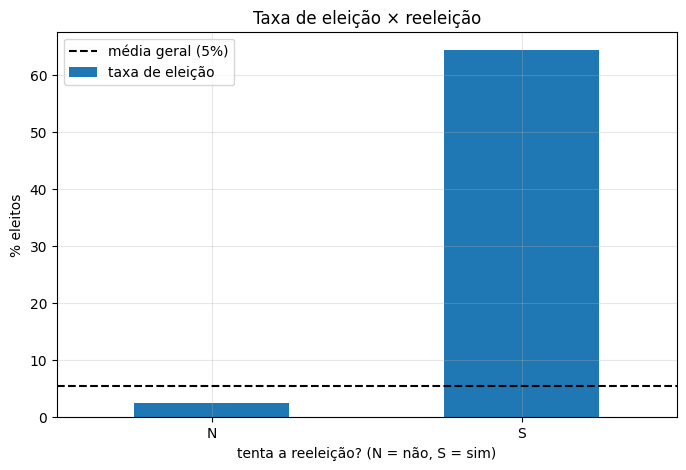

In [28]:
# Esta célula plota a taxa de eleição de quem tenta e de quem não tenta a reeleição.
(t_reeleicao["taxa de eleição"] * 100).plot.bar(color="C0", rot=0)
plt.axhline(df["eleito"].mean() * 100, color="black", ls="--", label="média geral (5%)")
plt.xlabel("tenta a reeleição? (N = não, S = sim)")
plt.ylabel("% eleitos")
plt.title("Taxa de eleição × reeleição")
plt.legend()
plt.show()

### **4.2. Gráfico 2: Patrimônio declarado**
Para explorar, tratamos quem não tem registro de bens como patrimônio **zero** (sem mexer na tabela original). Primeiro, a distribuição:

In [29]:
# Esta célula cria uma versão temporária do patrimônio, com zero para quem não tem registro de bens.
patrimonio = df["bens_total"].fillna(0)

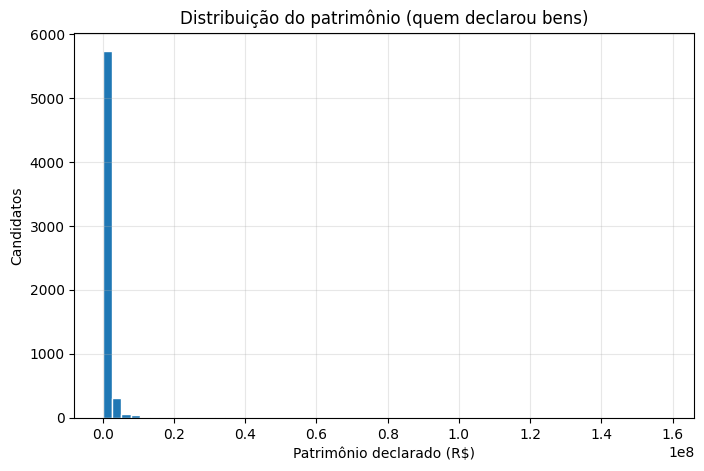

In [30]:
# Esta célula plota o histograma do patrimônio de quem declarou bens.
plt.hist(patrimonio[patrimonio > 0], bins=60, edgecolor="white")
plt.xlabel("Patrimônio declarado (R$)")
plt.ylabel("Candidatos")
plt.title("Distribuição do patrimônio (quem declarou bens)")
plt.show()

In [31]:
# Esta célula divide os candidatos em 6 faixas de patrimônio (pd.cut, com limites fixos) e conta quantos há em cada uma.
faixas_bens = pd.cut(patrimonio, bins=[-1, 0, 100_000, 500_000, 1_000_000, 5_000_000, np.inf],
                     labels=["sem bens", "até 100 mil", "100 a 500 mil", "500 mil a 1 mi", "1 a 5 mi", "mais de 5 mi"])
faixas_bens.value_counts().sort_index()

bens_total
sem bens          3254
até 100 mil       1738
100 a 500 mil     2162
500 mil a 1 mi     978
1 a 5 mi          1149
mais de 5 mi       195
Name: count, dtype: int64

In [32]:
# Esta célula calcula a taxa de eleição (em %) de cada faixa de patrimônio.
t_bens = df.groupby(faixas_bens, observed=True)["eleito"].mean() * 100
t_bens.round(1)

bens_total
sem bens           0.5
até 100 mil        2.2
100 a 500 mil      4.9
500 mil a 1 mi     9.7
1 a 5 mi          18.1
mais de 5 mi      25.6
Name: eleito, dtype: float64

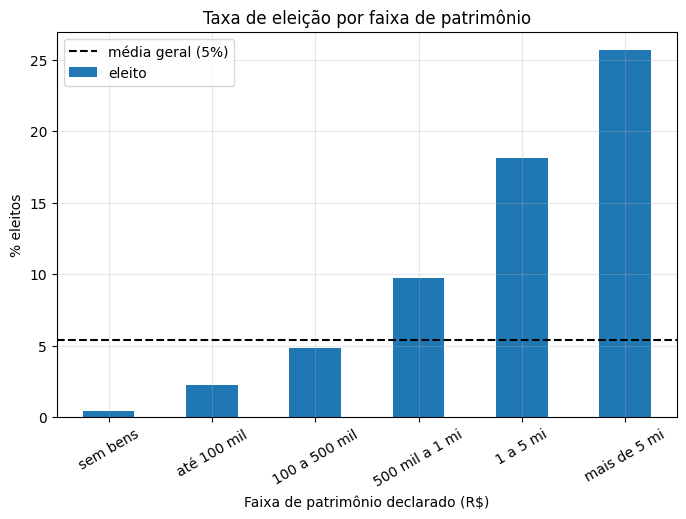

In [33]:
# Esta célula plota a taxa de eleição por faixa de patrimônio.
t_bens.plot.bar(color="C0", rot=30)
plt.axhline(df["eleito"].mean() * 100, color="black", ls="--", label="média geral (5%)")
plt.ylabel("% eleitos")
plt.xlabel("Faixa de patrimônio declarado (R$)")
plt.title("Taxa de eleição por faixa de patrimônio")
plt.legend()
plt.show()

### **4.3.    Gráfico 3: Escolaridade**

In [34]:
# Esta célula calcula o número de candidatos e a taxa de eleição (em %) de cada grau de escolaridade.
t_esc = df.groupby("escolaridade")["eleito"].agg(["mean", "count"])
t_esc["mean"] = t_esc["mean"] * 100
t_esc.columns = ["% eleitos", "candidatos"]
t_esc = t_esc.sort_values("% eleitos")
t_esc.round(1)

,% eleitos,candidatos
escolaridade,,
NÃO DIVULGÁVEL,0.0,2
LÊ E ESCREVE,0.0,76
ENSINO MÉDIO INCOMPLETO,1.1,190
ENSINO MÉDIO COMPLETO,1.2,2195
ENSINO FUNDAMENTAL INCOMPLETO,2.1,194
ENSINO FUNDAMENTAL COMPLETO,2.8,362
SUPERIOR INCOMPLETO,5.1,865
SUPERIOR COMPLETO,7.6,5592


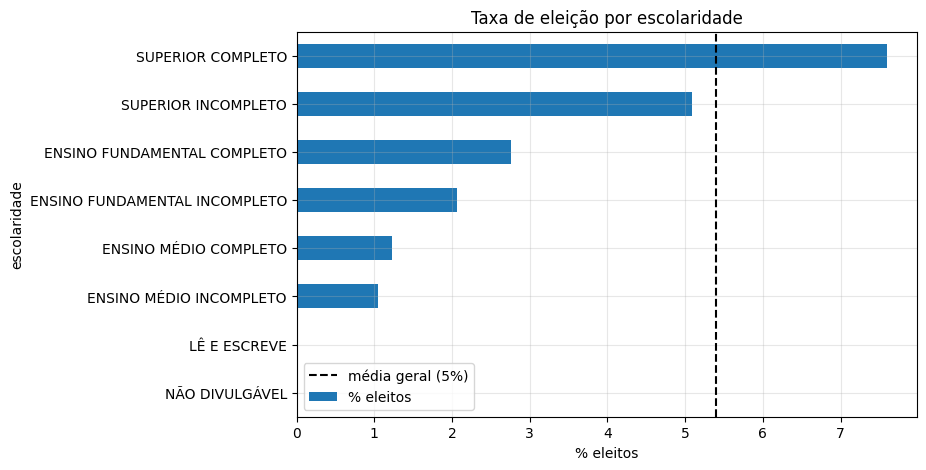

In [35]:
# Esta célula plota a taxa de eleição por escolaridade.
t_esc["% eleitos"].plot.barh(color="C0")
plt.axvline(df["eleito"].mean() * 100, color="black", ls="--", label="média geral (5%)")
plt.xlabel("% eleitos")
plt.title("Taxa de eleição por escolaridade")
plt.legend()
plt.show()

### **4.4.   Gráfico 4: Partido**

In [36]:
# Esta célula calcula o número de candidatos, de eleitos e a taxa de eleição (em %) de cada partido.
t_partido = df.groupby("partido")["eleito"].agg(candidatos="count", eleitos="sum", taxa="mean")
t_partido["taxa"] = t_partido["taxa"] * 100
t_partido = t_partido.sort_values("candidatos", ascending=False)
t_partido.round(1)

,candidatos,eleitos,taxa
partido,,,
REPUBLICANOS,505,40,7.9
UNIÃO,482,57,11.8
PP,476,47,9.9
PODE,476,13,2.7
PL,476,98,20.6
MDB,464,41,8.8
PTB,462,1,0.2
PDT,448,16,3.6
PATRIOTA,430,4,0.9


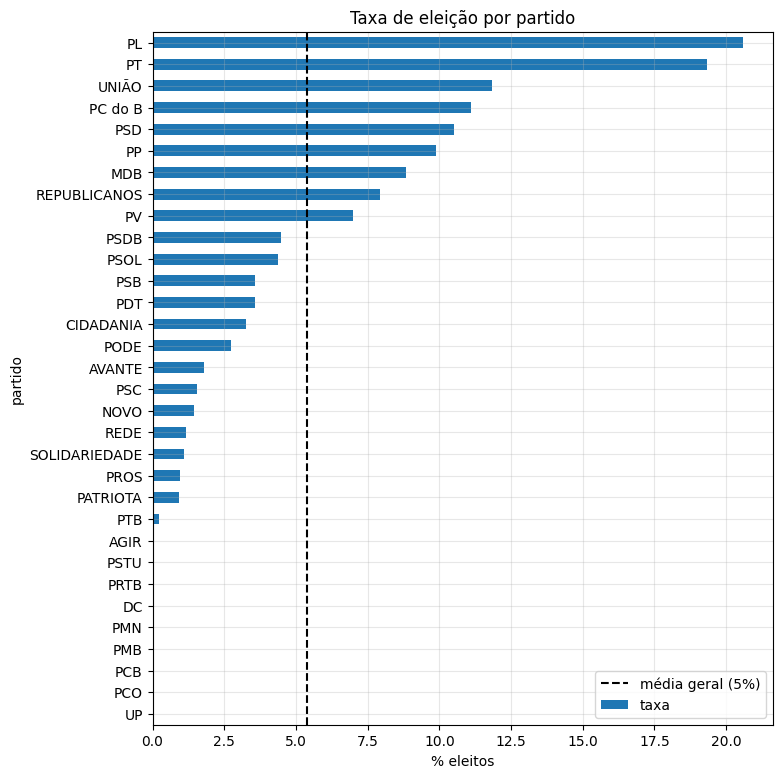

In [37]:
# Esta célula plota a taxa de eleição de cada partido.
t_partido["taxa"].sort_values().plot.barh(figsize=(8, 9), color="C0")
plt.axvline(df["eleito"].mean() * 100, color="black", ls="--", label="média geral (5%)")
plt.xlabel("% eleitos")
plt.title("Taxa de eleição por partido")
plt.legend()
plt.show()

---
## **5. Preparação dos dados para regressão logística**


In [38]:
# Esta célula cria uma cópia da tabela
dados = df.copy()

### **5.1.  Removendo os "intrusos"**
São só 2 candidatos, sem informação de escolaridade nem de reeleição, e **nenhum foi eleito**. Não há como usá-los:

In [39]:
# Esta célula remove as candidaturas com escolaridade ou reeleição "não divulgável".
antes = len(dados)
dados = dados[(dados["escolaridade"] != "NÃO DIVULGÁVEL") & (dados["reeleicao"].isin(["S", "N"]))].reset_index(drop=True)
print(f"Removidas: {antes - len(dados)} | Base final: {len(dados):,} candidatos | Eleitos: {dados['eleito'].sum()}")

Removidas: 2 | Base final: 9,474 candidatos | Eleitos: 512


### **5.2.  Reeleição: de texto para número**
`S` vira 1 e `N` vira 0:

In [40]:
# Esta célula transforma a reeleição em número: 1 = tenta a reeleição, 0 = não tenta.
dados["reeleicao"] = (dados["reeleicao"] == "S").astype(int)
dados["reeleicao"].value_counts()

reeleicao
0    9028
1     446
Name: count, dtype: int64

### **5.3.  Patrimônio: em faixas**
O patrimônio tem **cauda longa** (poucos valores gigantes), o que atrapalha a regressão logística. Uma solução simples: **dividir em faixas**, como fizemos nos gráficos. Quem não tem registro de bens vai para a faixa "sem bens":

In [41]:
# Esta célula cria a coluna faixa_bens: o patrimônio dividido em 6 faixas (quem não tem registro fica em "sem bens").
dados["faixa_bens"] = pd.cut(dados["bens_total"].fillna(0), bins=[-1, 0, 100_000, 500_000, 1_000_000, 5_000_000, np.inf],
                             labels=["sem bens", "até 100 mil", "100 a 500 mil", "500 mil a 1 mi", "1 a 5 mi", "mais de 5 mi"])
dados["faixa_bens"].value_counts().sort_index()

faixa_bens
sem bens          3252
até 100 mil       1738
100 a 500 mil     2162
500 mil a 1 mi     978
1 a 5 mi          1149
mais de 5 mi       195
Name: count, dtype: int64

### **5.4.  Escolaridade: juntando categorias pequenas**
Alguns graus têm pouquíssimos candidatos, e a taxa deles seria instável.

In [42]:
# Esta célula define o dicionário que agrupa os graus de escolaridade em 4 grupos.
ESC = {
    "SUPERIOR COMPLETO": "superior completo",
    "SUPERIOR INCOMPLETO": "superior incompleto",
    "ENSINO MÉDIO COMPLETO": "médio completo",
    "ENSINO MÉDIO INCOMPLETO": "até médio incompleto",
    "ENSINO FUNDAMENTAL COMPLETO": "até médio incompleto",
    "ENSINO FUNDAMENTAL INCOMPLETO": "até médio incompleto",
    "LÊ E ESCREVE": "até médio incompleto",
}
dados["escolaridade"] = dados["escolaridade"].map(ESC)
dados["escolaridade"].value_counts()

escolaridade
superior completo       5592
médio completo          2195
superior incompleto      865
até médio incompleto     822
Name: count, dtype: int64

### **5.5.  Partido: juntando os pequenos em "outros"**
Agrupamos em os que têm menos de 200 candidaturas.

In [43]:
# Esta célula agrupa em "outros" os partidos com menos de 200 candidaturas.
contagem_partido = dados["partido"].value_counts()
partidos_grandes = contagem_partido[contagem_partido >= 200].index
dados["partido"] = np.where(dados["partido"].isin(partidos_grandes), dados["partido"], "outros")
dados["partido"].value_counts()

partido
outros           758
REPUBLICANOS     505
UNIÃO            482
PL               476
PP               476
PODE             476
MDB              464
PTB              462
PDT              448
PATRIOTA         430
PSB              420
PSD              399
PSC              390
AVANTE           389
SOLIDARIEDADE    364
PT               357
PROS             312
AGIR             310
PSOL             297
PSDB             291
PRTB             286
PMN              263
DC               212
NOVO             207
Name: count, dtype: int64

### **5.6.    Transformando categorias em colunas 0/1 (`get_dummies`)**
A regressão logística só entende números. O `pd.get_dummies` cria **uma coluna 0/1 para cada categoria**.

Uma categoria de cada variável fica de fora: é a **categoria de referência**, e os resultados serão comparados **com ela**. Escolhemos: partido **"outros"**, escolaridade **"até médio incompleto"** e patrimônio **"sem bens"**.

In [44]:
# Esta célula transforma partido, escolaridade e faixa de patrimônio em colunas de 0 e 1.
X_cat = pd.get_dummies(dados[["partido", "escolaridade", "faixa_bens"]], dtype=int)
X_cat.shape

(9474, 34)

In [45]:
# Esta célula retira as categorias de referência (uma de cada variável).
X_cat = X_cat.drop(columns=["partido_outros", "escolaridade_até médio incompleto", "faixa_bens_sem bens"])
colunas_A = X_cat.columns.tolist()
print(f"{len(colunas_A)} colunas no Modelo A")

31 colunas no Modelo A


In [46]:
# Esta célula monta a tabela de atributos X do Modelo B (as colunas do Modelo A mais a reeleição) e a resposta y.
X = pd.concat([X_cat, dados[["reeleicao"]]], axis=1)
y = dados["eleito"]
print(f"{X.shape[1]} colunas no Modelo B")
X.head(3)

32 colunas no Modelo B


,partido_AGIR,partido_AVANTE,partido_DC,partido_MDB,partido_NOVO,partido_PATRIOTA,partido_PDT,partido_PL,partido_PMN,partido_PODE,...,partido_UNIÃO,escolaridade_médio completo,escolaridade_superior completo,escolaridade_superior incompleto,faixa_bens_até 100 mil,faixa_bens_100 a 500 mil,faixa_bens_500 mil a 1 mi,faixa_bens_1 a 5 mi,faixa_bens_mais de 5 mi,reeleicao
0,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [47]:
# Esta célula divide os candidatos em treino (80%) e teste (20%), mantendo a mesma proporção de eleitos nos dois.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Treino: {len(X_train):,} candidatos | Teste: {len(X_test):,} candidatos")
print(f"Eleitos no treino: {y_train.mean():.1%} | no teste: {y_test.mean():.1%}")

Treino: 7,579 candidatos | Teste: 1,895 candidatos
Eleitos no treino: 5.4% | no teste: 5.4%


---
## **6. Os modelos**

### **6.1.  M0: o baseline ("burro")**
Sempre prevê a classe mais frequente (não eleito).

In [48]:
# Esta célula cria e treina o modelo de referência, que sempre prevê "não eleito".
modelo_0 = DummyClassifier(strategy="most_frequent")
modelo_0.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.95,0.05]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](32,)","['partido_AGIR','partido_AVANTE','partido_DC',...,'faixa_bens_1 a 5 mi', 'faixa_bens_mais de 5 mi','reeleicao']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,32
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


### **6.2.  Modelo A: partido + escolaridade + patrimônio**
Usa **só o perfil** do candidato (sem a reeleição).

In [49]:
# Esta célula cria e treina o Modelo A usando só as colunas de perfil (sem a reeleição).
modelo_A = LogisticRegression(max_iter=1000)
modelo_A.fit(X_train[colunas_A], y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### **6.3.  Modelo B: Modelo A + reeleição**
Mesmo modelo, mesmos candidatos de treino, com uma coluna a mais.

In [50]:
# Esta célula cria e treina o Modelo B usando todas as colunas (perfil + reeleição).
modelo_B = LogisticRegression(max_iter=1000)
modelo_B.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Avaliação do modelo B

In [51]:
# Esta célula sorteia 4 candidatos eleitos e 4 não eleitos do conjunto de teste.
amostra = pd.concat([X_test[y_test == 1].sample(4, random_state=3), X_test[y_test == 0].sample(4, random_state=3)])

In [52]:
# Esta célula mostra o perfil, a probabilidade de eleição dada pelo Modelo B e o desfecho real de cada candidato.
perfil = dados.loc[amostra.index, ["partido", "escolaridade", "faixa_bens"]].copy()
perfil["tenta reeleição"] = np.where(dados.loc[amostra.index, "reeleicao"] == 1, "sim", "não")
perfil["P(eleito)"] = (modelo_B.predict_proba(amostra)[:, 1] * 100).round(1).astype(str) + "%"
perfil["real"] = np.where(y_test.loc[amostra.index] == 1, "eleito", "não eleito")
perfil

,partido,escolaridade,faixa_bens,tenta reeleição,P(eleito),real
4773,UNIÃO,superior completo,1 a 5 mi,sim,77.7%,eleito
4216,PT,superior completo,500 mil a 1 mi,sim,75.9%,eleito
7453,PT,superior completo,1 a 5 mi,sim,86.0%,eleito
2745,UNIÃO,superior incompleto,100 a 500 mil,sim,70.4%,eleito
5058,PMN,até médio incompleto,100 a 500 mil,não,0.5%,não eleito
54,PODE,superior completo,100 a 500 mil,não,2.7%,não eleito
994,AGIR,médio completo,sem bens,não,0.1%,não eleito
2160,PSB,médio completo,100 a 500 mil,não,1.1%,não eleito


---
## **7. Avaliação**

| Métrica | Leitura |
|---|---|
| **Acurácia** | % de candidatos classificados corretamente |
| **Precisão** | dos candidatos que o modelo **apontou** como eleitos, quantos realmente foram |
| **Recall** | dos candidatos que **realmente** foram eleitos, quantos o modelo **encontrou** |
| **F1** | média harmônica entre precisão e recall |
| **AUC** | capacidade de **ordenar** quem tem mais chance (0,5 = chute; 1 = perfeito) |

Para não repetir contas, criamos uma **função pronta**: o modelo decide "eleito" quando a probabilidade for maior ou igual ao **corte** (por padrão, 0,5).

In [53]:
# Esta célula cria a função avaliar: calcula acurácia, precisão, recall, F1 e AUC de um modelo no teste.
def avaliar(modelo, X_te, corte=0.5):
    proba = modelo.predict_proba(X_te)[:, 1]
    pred = (proba >= corte).astype(int)
    return pd.Series({
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba),
    })

In [54]:
# Esta célula compara o baseline e os dois modelos no conjunto de teste, com corte 0,5.
comparativo = pd.DataFrame({
    "M0 Baseline": avaliar(modelo_0, X_test),
    "Modelo A (perfil)": avaliar(modelo_A, X_test[colunas_A]),
    "Modelo B (perfil + reeleição)": avaliar(modelo_B, X_test),
}).T
comparativo.round(3)

,Acurácia,Precisão,Recall,F1,AUC
M0 Baseline,0.946,0.000,0.000,0.000,0.50
Modelo A (perfil),0.945,0.200,0.010,0.019,0.89
Modelo B (perfil + reeleição),0.960,0.701,0.461,0.556,0.93


**O que a tabela mostra:** A reeleição melhora bastante o modelo.

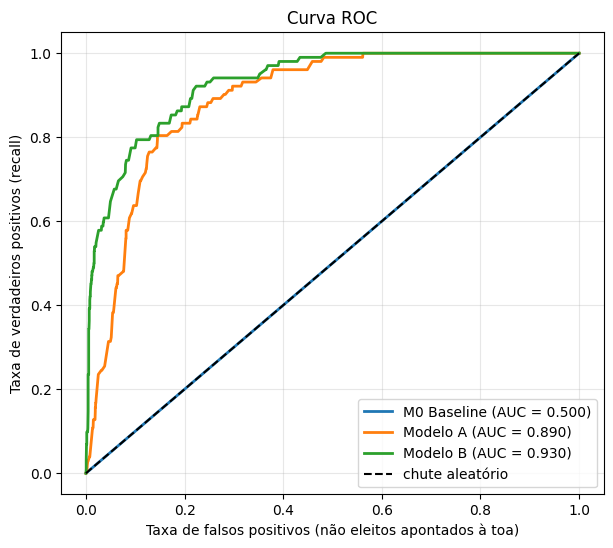

In [55]:
# Esta célula desenha a curva ROC dos três modelos (quanto mais perto do canto superior esquerdo, melhor).
plt.figure(figsize=(7, 6))
for nome, modelo, Xte in [("M0 Baseline", modelo_0, X_test), ("Modelo A", modelo_A, X_test[colunas_A]), ("Modelo B", modelo_B, X_test)]:
    proba = modelo.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nome} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chute aleatório")
plt.xlabel("Taxa de falsos positivos (não eleitos apontados à toa)")
plt.ylabel("Taxa de verdadeiros positivos (recall)")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.show()

---
## **8.  A matriz de confusão**

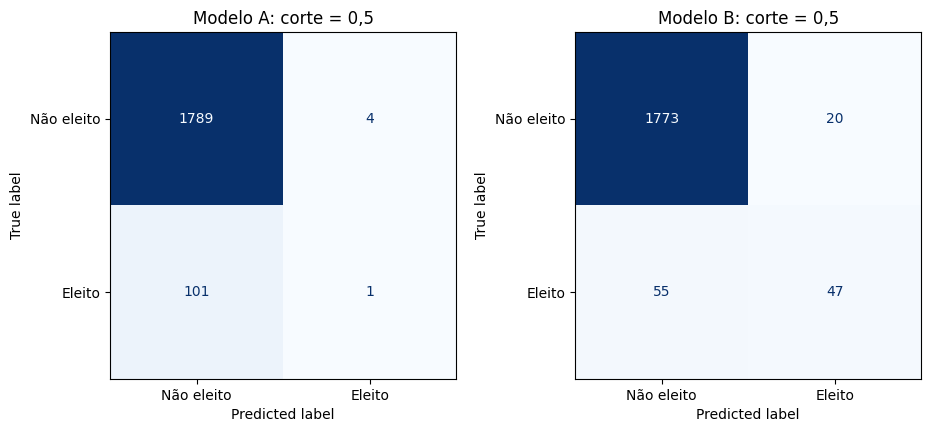

In [56]:
# Esta célula exibe as matrizes de confusão do Modelo A e do Modelo B, lado a lado, com corte 0,5.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, modelo, Xte, titulo in [(axes[0], modelo_A, X_test[colunas_A], "Modelo A"), (axes[1], modelo_B, X_test, "Modelo B")]:
    ConfusionMatrixDisplay.from_predictions(y_test, modelo.predict(Xte), display_labels=["Não eleito", "Eleito"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.grid(False)
    ax.set_title(f"{titulo}: corte = 0,5")
plt.show()

In [57]:
# Esta célula explica em palavras cada quadrante da matriz de confusão do Modelo B.
vn, fp, fn, vp = confusion_matrix(y_test, modelo_B.predict(X_test)).ravel()
print(f"Verdadeiros negativos (não eleito e acertamos):            {vn:,}")
print(f"Falsos positivos      (apontamos, mas não foi eleito):     {fp:,}")
print(f"Falsos negativos      (não apontamos, mas foi eleito):     {fn:,}")
print(f"Verdadeiros positivos (eleito e acertamos):                {vp:,}")

Verdadeiros negativos (não eleito e acertamos):            1,773
Falsos positivos      (apontamos, mas não foi eleito):     20
Falsos negativos      (não apontamos, mas foi eleito):     55
Verdadeiros positivos (eleito e acertamos):                47
